In [11]:
# Libraries

%load_ext autoreload
%autoreload 2

import sys
import json
import math
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.tokenizer import CharTokenizer
from src.attention import scaled_dot_product_attention

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
# Tokenizer

TOKENIZER_PATH = (
    PROJECT_ROOT / "data" / "processed" / "tokenizer.json"
)

with open(TOKENIZER_PATH, "r", encoding="utf-8") as file:
    tokenizer_state = json.load(file)

tokenizer = CharTokenizer.from_dict(tokenizer_state)

print("Vocabulary size:", tokenizer.vocab_size)


# Input sequence

prompt = "ROMEO:\n"

characters = list(prompt)
token_ids = tokenizer.encode(prompt)

print("Characters:", characters)
print("Token IDs:", token_ids)


# Embedding

torch.manual_seed(42)

d_model = 8
head_size = 4

embedding = nn.Embedding(
    tokenizer.vocab_size,
    d_model
)

x = embedding(
    torch.tensor([token_ids], dtype=torch.long)
)

print("Embedding shape:", x.shape)

Vocabulary size: 65
Characters: ['R', 'O', 'M', 'E', 'O', ':', '\n']
Token IDs: [30, 27, 25, 17, 27, 10, 0]
Embedding shape: torch.Size([1, 7, 8])


In [13]:
# Q K V

query_layer = nn.Linear(
    d_model,
    head_size,
    bias=False
)

key_layer = nn.Linear(
    d_model,
    head_size,
    bias=False
)

value_layer = nn.Linear(
    d_model,
    head_size,
    bias=False
)

Q = query_layer(x)
K = key_layer(x)
V = value_layer(x)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: torch.Size([1, 7, 4])
K shape: torch.Size([1, 7, 4])
V shape: torch.Size([1, 7, 4])


In [14]:
# Attention Scores

scores = torch.matmul(
    Q,
    K.transpose(-2, -1)
)

scores = scores / math.sqrt(head_size)

print("Attention Scores shape:", scores.shape)

display(
    pd.DataFrame(
        scores[0].detach().numpy(),
        index=characters,
        columns=characters
    )
)

Attention Scores shape: torch.Size([1, 7, 7])


,R,O,M,E,O,:,\n
R,0.055392,-0.144933,0.070741,0.058142,-0.144933,0.394726,-0.482423
O,0.195843,0.193731,0.281805,0.315677,0.193731,0.455608,-0.592509
M,0.205858,0.581744,0.369290,0.294809,0.581744,0.107400,-0.100138
E,0.038814,-0.036947,0.017029,-0.103217,-0.036947,0.200719,-0.130019
O,0.195843,0.193731,0.281805,0.315677,0.193731,0.455608,-0.592509
:,-0.047022,-0.103124,0.009847,0.405821,-0.103124,-0.118929,-0.226527
\n,0.220401,0.982428,0.302840,-0.454171,0.982428,-0.178790,0.883762


In [15]:
# Causal Mask 

T = len(characters)

causal_mask = torch.tril(
    torch.ones(T, T, dtype=torch.bool)
)

display(
    pd.DataFrame(
        causal_mask.numpy().astype(int),
        index=characters,
        columns=characters
    )
)

masked_scores = scores.masked_fill(
    ~causal_mask,
    float("-inf")
)

display(
    pd.DataFrame(
        masked_scores[0].detach().numpy(),
        index=characters,
        columns=characters
    )
)

,R,O,M,E,O,:,\n
R,1,0,0,0,0,0,0
O,1,1,0,0,0,0,0
M,1,1,1,0,0,0,0
E,1,1,1,1,0,0,0
O,1,1,1,1,1,0,0
:,1,1,1,1,1,1,0
\n,1,1,1,1,1,1,1


,R,O,M,E,O,:,\n
R,0.055392,-inf,-inf,-inf,-inf,-inf,-inf
O,0.195843,0.193731,-inf,-inf,-inf,-inf,-inf
M,0.205858,0.581744,0.369290,-inf,-inf,-inf,-inf
E,0.038814,-0.036947,0.017029,-0.103217,-inf,-inf,-inf
O,0.195843,0.193731,0.281805,0.315677,0.193731,-inf,-inf
:,-0.047022,-0.103124,0.009847,0.405821,-0.103124,-0.118929,-inf
\n,0.220401,0.982428,0.302840,-0.454171,0.982428,-0.178790,0.883762


In [16]:
# Softmax for attention

attention_weights = F.softmax(
    masked_scores,
    dim=-1
)

print("Attention Weights:")

display(
    pd.DataFrame(
        attention_weights[0].detach().numpy(),
        index=characters,
        columns=characters
    )
)

Attention Weights:


,R,O,M,E,O,:,\n
R,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
O,0.500528,0.499472,0.000000,0.000000,0.000000,0.000000,0.000000
M,0.275192,0.400757,0.324051,0.000000,0.000000,0.000000,0.000000
E,0.265035,0.245698,0.259324,0.229943,0.000000,0.000000,0.000000
O,0.191833,0.191429,0.209053,0.216256,0.191429,0.000000,0.000000
:,0.154972,0.146517,0.164040,0.243736,0.146517,0.144219,0.000000
\n,0.105344,0.225712,0.114396,0.053660,0.225712,0.070671,0.204505


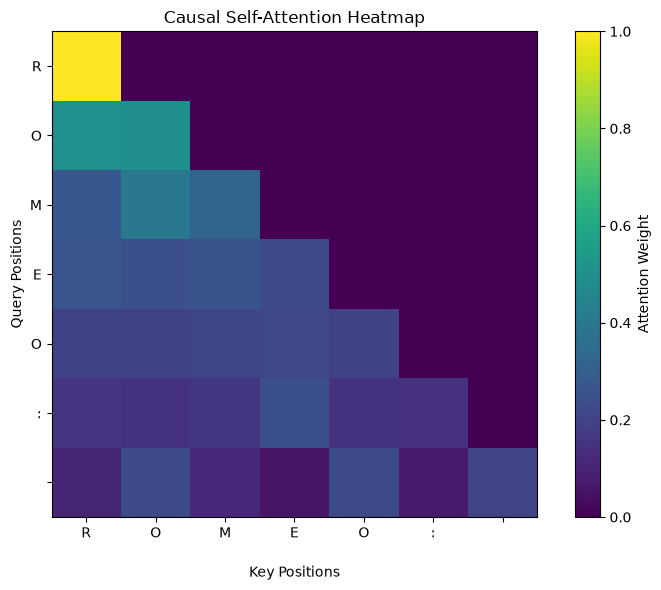

In [17]:
# Visualize

plt.figure(figsize=(8, 6))

plt.imshow(
    attention_weights[0].detach().numpy(),
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Attention Weight")

plt.xticks(
    range(T),
    characters
)

plt.yticks(
    range(T),
    characters
)

plt.xlabel("Key Positions")
plt.ylabel("Query Positions")

plt.title("Causal Self-Attention Heatmap")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "attention_heatmap_demo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Weighted sum of Value

output = torch.matmul(
    attention_weights,
    V
)

print("Output shape:", output.shape)

Output shape: torch.Size([1, 7, 4])


In [19]:
# Compare with src

output_src, weights_src = scaled_dot_product_attention(
    Q,
    K,
    V,
    mask=causal_mask
)

print(
    "Output matches:",
    torch.allclose(output, output_src, atol=1e-6)
)

print(
    "Weights match:",
    torch.allclose(
        attention_weights,
        weights_src,
        atol=1e-6
    )
)

Output matches: True
Weights match: True


In [20]:
# Mask vs no Mask 

unmasked_weights = F.softmax(
    scores,
    dim=-1
)

query_index = 0

print("Query token:", characters[query_index])

print("\nAttention without mask:")

display(
    pd.Series(
        unmasked_weights[0, query_index].detach().numpy(),
        index=characters
    )
)

print("\nAttention with causal mask:")

display(
    pd.Series(
        attention_weights[0, query_index].detach().numpy(),
        index=characters
    )
)

Query token: R

Attention without mask:


R     0.150530
O     0.123204
M     0.152859
E     0.150945
O     0.123204
:     0.211346
\n    0.087913
dtype: float32


Attention with causal mask:


R     1.0
O     0.0
M     0.0
E     0.0
O     0.0
:     0.0
\n    0.0
dtype: float32